# Lens optimization with damped least squares: from a singlet to an achromat, a Cooke triplet and a microscope objective

A lens design program does not invent a lens. It takes a starting system,
a list of **variables** (curvatures, thicknesses, glasses, conics, aspheric
terms), a list of **operands** that say what is wrong with the system
(a focal length that is off, ray errors, wavefront error, Seidel sums,
colour), and changes the variables until the weighted sum of squares of
the operands, the **merit function**, is as small as it gets

$$
\Phi(\mathbf x) = \sum_i r_i(\mathbf x)^2, \qquad r_i = w_i\,\frac{f_i(\mathbf x) - t_i}{\text{tol}_i}.
$$

Since the 1960s the workhorse for this has been **damped least squares**
(DLS), the method of Levenberg (1944) and Marquardt (1963), introduced into
lens design by Wynne (1959), Wynne and Wormell (1963) and Spencer (1963).
Around the current variables the operands are linearized with the
Jacobian $J_{ik} = \partial r_i/\partial x_k$, and the step $\Delta\mathbf x$
solves

$$
\left(J^\mathsf{T} J + \lambda D\right)\Delta\mathbf x = -J^\mathsf{T}\mathbf r,
\qquad D = \operatorname{diag}(J^\mathsf{T} J).
$$

For $\lambda = 0$ this is the Gauss-Newton step to the minimum of the
linearized problem. It is exact for linear operands, but lens operands are
strongly non-linear and $J^\mathsf{T} J$ is nearly singular (many
variables do almost the same thing), so the Gauss-Newton step is often far
too long. The damping $\lambda$ shortens it and turns it towards the
(scaled) steepest descent. $\lambda$ adapts: it shrinks after a good step
and grows after a step that made $\Phi$ worse.

Two more ingredients make a lens design program:

- **Solves** hold first order properties exactly after every change: the
  image plane in the paraxial focus, the curvature of the last surface for
  the focal length, the stop size for the F-number.
- **Constraints** that must hold, rather than being small, such as a focal
  length, colour correction, edge thicknesses or a total length, are kept by
  **Lagrange multipliers** $\boldsymbol\mu$ (Spencer 1963): the linearized
  active constraints $A\,\Delta\mathbf x = \mathbf b$ are added to the step,

$$
\begin{pmatrix} J^\mathsf{T} J + \lambda D & A^\mathsf{T} \\ A & 0 \end{pmatrix}
\begin{pmatrix} \Delta\mathbf x \\ \boldsymbol\mu \end{pmatrix} =
\begin{pmatrix} -J^\mathsf{T}\mathbf r \\ \mathbf b \end{pmatrix}.
$$

  Inequalities (an edge thickness of at least 1 mm) are active only when
  they are violated or the step would violate them.

The Jacobian is built by finite differences. Its columns are the
**sensitivities** of the operands to the variables, the same changes of the
system that tolerancing uses (`System.with_radius_change()`,
`with_axial_shift()`, `with_index_change()`). pyoptics has two optimizers
in `lens_optimization`: `LensOptimizer` (scipy's trust region least squares,
used for the KrF lens of notebook 43) and `DampedLeastSquares`, the
classical lens design optimizer with variables, solves and constraints that
this notebook uses. It goes through

1. the DLS step itself on a singlet with two curvatures: the merit function
   landscape, Gauss-Newton against damped steps,
2. a singlet turned into a cemented achromat: focal length and colour as
   constraints, spherical aberration and coma from the Seidel sums as
   operands, model glasses that move on the glass map, a search of the
   glass catalogue for the aplanatic pair, and the real ray finish at three
   wavelengths,
3. a Cooke triplet (F/4.5, ±20°) from a rough start: real ray errors at
   three wavelengths and fields, solves for focal length and F-number, edge
   thickness and length constraints; the
   Jacobian as a table of sensitivities of the Seidel sums, the Seidel sums
   surface by surface with the pupil closeness of the surfaces, and the
   Lagrange multiplier of the length as the price of a constraint.
4. a 10x/0.25 microscope objective: the Lister objective of two
   achromats, diffraction limited on axis but with a curved field, the
   Petzval sum as the reason, and a plan objective with lanthanum crowns
   and a thick meniscus that the optimizer shapes into a flat field.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics.materials import LAMBDA_F, LAMBDA_C, LAMBDA_d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

WL_F, WL_d, WL_C = LAMBDA_F*1e-6, LAMBDA_d*1e-6, LAMBDA_C*1e-6  # mm
COLORS = {"F": "#2a78d6", "d": "#1baf7a", "C": "#d03b3b"}
BK7 = lo.GLASSES["N-BK7"]

## 1. The damped least squares step

A singlet of N-BK7, 5 mm thick, f = 100 mm at F/5 with the stop on the
first surface, has two variables: the curvatures $c_1$ and $c_2$. Two
operands: the focal length (target 100 mm, tolerance 0.1 mm) and the
Seidel spherical aberration $W_{040}$ (target 0, tolerance 0.1 waves). The
focal length fixes the power, so the solutions lie on a line
$c_1 - c_2 \approx \text{const}$ in the $(c_1, c_2)$ plane, and along that line
(the bending) $W_{040}$ has a minimum but no zero: a singlet cannot be free
of spherical aberration. The merit function is a long, narrow, curved
valley, the typical landscape of lens design. Its condition number (the
ratio of the largest and smallest eigenvalue of $J^\mathsf{T}J$) shows how
stretched it is.

In [2]:
def singlet(c1, c2, t=5.0, f_back=95.0, glass=BK7, epd=20.0, field_deg=1.0):
    S = [rt.Surface(1/c1 if c1 else np.inf, t, material=glass),
         rt.Surface(1/c2 if c2 else np.inf, f_back, n_after=1.0)]

    return rt.System(S, 0, WL_d, field_angle=np.deg2rad(field_deg), entrance_pupil_radius=epd/2)


ops_singlet = [lo.paraxial_target("efl", 100.0, 0.1), lo.seidel("W040", 0.0, 0.1)]
c1s = np.linspace(-0.005, 0.03, 141)
c2s = np.linspace(-0.035, 0.005, 141)
merit = np.zeros((len(c2s), len(c1s)))
for i, c2 in enumerate(c2s):
    for j, c1 in enumerate(c1s):
        s = singlet(c1, c2)
        merit[i, j] = np.sum(np.concatenate([op(s) for op in ops_singlet])**2)

start = (0.0, -0.002)  # nearly flat: much too weak
paths = {}
for name, lam in [("Gauss-Newton, λ = 0", 0.0), ("damped, λ = 0.3", 0.3), ("adaptive λ (run())", None)]:
    opt = lo.DampedLeastSquares(singlet(*start), [lo.Curvature(0), lo.Curvature(1)], ops_singlet)
    pts = [opt.x]
    if lam is None:
        res = opt.run(max_iterations=30)
        pts = [h["x"] for h in res.history]
    else:
        for _ in range(12):
            opt.system = opt.system_at(opt.x + opt.step(lam))
            pts.append(opt.x)
    paths[name] = np.array(pts)
    print(f"{name:24s} c1 = {pts[-1][0]: .5f}, c2 = {pts[-1][1]: .5f}, merit {opt.merit():.4g}")

J = opt.jacobian()[0]
JD = J*opt._scale
print(f"condition number of J^T J at the minimum (scaled variables): "
      f"{np.linalg.cond(JD.T @ JD):.3g}")
c1_opt, c2_opt = paths["adaptive λ (run())"][-1]
print(f"shape factor (c1 + c2)/(c1 - c2) = {(c1_opt + c2_opt)/(c1_opt - c2_opt):.3f} "
      "(thin lens theory for minimum spherical aberration: 0.74)")

Gauss-Newton, λ = 0      c1 =  0.03780, c2 =  0.01874, merit 6.964e+04
damped, λ = 0.3          c1 =  0.01041, c2 = -0.00889, merit 3735
adaptive λ (run())       c1 =  0.01666, c2 = -0.00266, merit 1813
condition number of J^T J at the minimum (scaled variables): 4.99e+10
shape factor (c1 + c2)/(c1 - c2) = 0.724 (thin lens theory for minimum spherical aberration: 0.74)


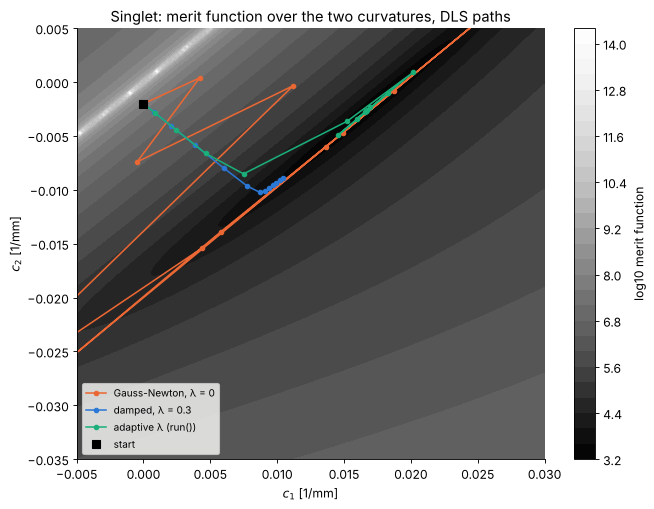

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
C1, C2 = np.meshgrid(c1s, c2s)
cs = ax.contourf(C1, C2, np.log10(merit), levels=30, cmap="Greys_r")
fig.colorbar(cs, ax=ax, label="log10 merit function")
for (name, P), col in zip(paths.items(), ["#eb6834", "#2a78d6", "#1baf7a"]):
    ax.plot(P[:, 0], P[:, 1], "o-", color=col, ms=4, lw=1.4, label=name)
ax.plot(*start, "ks", ms=7, label="start")
ax.set_xlim(c1s[0], c1s[-1])
ax.set_ylim(c2s[0], c2s[-1])
ax.set_xlabel("$c_1$ [1/mm]")
ax.set_ylabel("$c_2$ [1/mm]")
ax.set_title("Singlet: merit function over the two curvatures, DLS paths")
ax.legend(loc="lower left", fontsize=9)
ax.grid(False)
fig.tight_layout()

The valley runs along the lenses of 100 mm focal length; across it the
merit function rises many orders of magnitude faster than along it.
Gauss-Newton ($\lambda = 0$) trusts the linear model completely: its steps
jump across the valley and then far along it, beyond the minimum, because
the operands are not linear in the curvatures, and it does not converge.
A fixed damping $\lambda = 0.3$ is safe but slow: after twelve steps it is
still creeping along the valley floor. The adaptive damping of `run()`
combines both, long steps where the linear model holds and short ones
where it fails, and ends at the bending of least spherical aberration,
close to the thin lens shape factor of about 0.74 (Kingslake).

## 2. From a singlet to an achromat

### 2.1 Colour of the singlet

**The lines F, d and C.** Optical glass is specified at a few sharp
spectral lines that were easy to produce in the laboratory, named after
Fraunhofer's letters for the dark lines of the solar spectrum:

| line | wavelength | source | colour |
|---|---|---|---|
| F | 486.13 nm | hydrogen (H-β) | blue |
| d | 587.56 nm | helium | yellow |
| C | 656.27 nm | hydrogen (H-α) | red |
| g | 435.83 nm | mercury | violet (used for the secondary spectrum) |

d lies near the peak of the eye's sensitivity and is the design (or
primary) wavelength: the focal length, $n_d$ and the paraxial data refer
to it. F and C mark the ends of the visual band, and their index
difference $n_F - n_C$, the *principal dispersion*, measures how much the
glass spreads the colours. The Abbe number $V_d = (n_d - 1)/(n_F - n_C)$
compares the dispersion with the refracting power: a large $V_d$ (crowns,
about 50 to 95) means little dispersion, a small one (flints, about 20 to
50) much. "Colour corrected" for a visual lens classically means that F
and C share one focus (`pyoptics.glasses.LINES` has these and more
lines; other bands use other lines, e.g. e, F' and C' in Europe today, or
laser lines).


The index of N-BK7 falls with the wavelength, so the singlet's blue focus
lies in front of its red one: about $f/V_d = 1.6$ mm between F (486 nm)
and C (656 nm) for $V_d = 64$. The thin lens achromat (Fraunhofer, Hall)
splits the power between a crown and a flint with powers

$$
\varphi_1 = \varphi\,\frac{V_1}{V_1 - V_2}, \qquad \varphi_2 = -\varphi\,\frac{V_2}{V_1 - V_2},
$$

so that their dispersions cancel. With N-BK7 and N-F2 cemented,
equiconvex crown first, this is the starting point of the optimization.

In [4]:
def doublet(crown, flint, f=100.0, t1=5.0, t2=2.5, epd=20.0, field_deg=1.0):
    """Thin lens achromat, crown equiconvex, cemented."""
    (n1, V1), (n2, V2) = crown, flint
    p1, p2 = V1/(V1 - V2)/f, -V2/(V1 - V2)/f
    c1 = p1/(n1 - 1)/2
    c2 = -c1
    c3 = c2 - p2/(n2 - 1)
    S = [rt.Surface(1/c1, t1, material=crown), rt.Surface(1/c2, t2, material=flint),
         rt.Surface(1/c3, f, n_after=1.0)]
    s = rt.System(S, 0, WL_d, field_angle=np.deg2rad(field_deg), entrance_pupil_radius=epd/2)

    return s.at_paraxial_focus()


best_singlet = singlet(c1_opt, c2_opt).at_paraxial_focus()
start_doublet = doublet(BK7, lo.GLASSES["N-F2"])
wl_scan = np.linspace(430e-6, 720e-6, 60)


def focus_curve(s):
    z = np.array([s.with_wavelength(w).paraxial().image_distance for w in wl_scan])
    return z - s.paraxial().image_distance


for name, s in [("singlet", best_singlet), ("thin lens achromat N-BK7/N-F2", start_doublet)]:
    p, sd = s.paraxial(), s.seidel()
    dz = s.with_wavelength(WL_F).paraxial().image_distance - s.with_wavelength(WL_C).paraxial().image_distance
    print(f"{name:32s} efl {p.efl:7.3f} mm, F - C focus {dz*1e3:8.1f} um, "
          f"W040 {sd.W040:6.2f}, W131 {sd.W131:6.2f} waves")

singlet                          efl 100.530 mm, F - C focus  -1538.0 um, W040  -4.23, W131   0.18 waves
thin lens achromat N-BK7/N-F2    efl  99.513 mm, F - C focus    -91.0 um, W040  -1.12, W131  -1.47 waves


### 2.2 Focal length and colour as constraints

Three curvatures are the variables, the image plane follows the paraxial
focus (a solve). The focal length (100 mm) and the paraxial F - C focus
difference (0) are **constraints**: they hold exactly after every step.
What is left (one degree of freedom, the bending of the doublet) corrects
the operand, the spherical aberration $W_{040}$. Then coma $W_{131}$ is
added as a second operand.

In [5]:
def efl_constraint(f=100.0):
    return lo.Constraint(lo.paraxial_value("efl"), f, f, tolerance=1e-3, name="efl")


def colour_constraint():
    def f_minus_c(s):
        return lo.focal_shift(WL_F, WL_C, tolerance=1.0)(s)[0]
    return lo.Constraint(f_minus_c, 0.0, 0.0, tolerance=1e-4, name="F - C focus")


cons = [efl_constraint(), colour_constraint()]
focus = [lo.solve_paraxial_focus()]
opt_sa = lo.DampedLeastSquares(start_doublet, lo.curvatures(start_doublet),
                               [lo.seidel("W040", 0.0, 0.01)], cons, solves=focus)
res_sa = opt_sa.run()
print(res_sa.message, "after", len(res_sa.history) - 1, "iterations")
print(opt_sa.report(["W040 (tol 0.01 waves)"]))

ops_aplanat = [lo.seidel("W040", 0.0, 0.01), lo.seidel("W131", 0.0, 0.01)]
opt_ap = lo.DampedLeastSquares(start_doublet, lo.curvatures(start_doublet), ops_aplanat, cons,
                               solves=focus)
res_ap = opt_ap.run()
print()
print(opt_ap.report(["W040 (tol 0.01 waves)", "W131 (tol 0.01 waves)"]))
sd = res_ap.system.seidel()
print(f"W040 = {sd.W040:.3f}, W131 = {sd.W131:.3f} waves at 1°")

no step lowers the merit function (local minimum) after 7 iterations
merit function 0
  W040 (tol 0.01 waves)                   0     0.0 %
  efl                          [100.]  [100.0, 100.0]  ok
  F - C focus                  [0.]  [0.0, 0.0]  ok



merit function 15927.9
  W040 (tol 0.01 waves)              3083.2    19.4 %
  W131 (tol 0.01 waves)               12845    80.6 %
  efl                          [100.]  [100.0, 100.0]  ok
  F - C focus                  [-4.7082e-10]  [0.0, 0.0]  ok
W040 = 0.555, W131 = -1.133 waves at 1°


With N-BK7 and N-F2 the doublet can be free of colour and of spherical
aberration, but not of coma at the same time: with focal length and colour
fixed, the three curvatures leave only the bending, one variable for two
aberrations. The classical way out is the choice of the glasses: for a
cemented doublet there is a pair of glasses for which both vanish at
once, an *aplanatic* achromat.

### 2.3 Model glasses on the glass map

A glass is a point $(n_d, V_d)$ on the glass map. As a variable it moves
continuously (a *model glass*, `lo.glass()`; its dispersion is the Abbe
model of `materials.abbe_dispersion()`). Not every point is a real glass:
glasses fill a region bounded by the "glass line" of the crowns and flints
at low index and by the lanthanum glasses at high index, and a constraint
(`lo.glass_map_constraint()`) keeps the model glasses inside. With both
glasses free there are seven variables for two constraints and two
operands.

In [6]:
var_glass = lo.curvatures(start_doublet) + lo.glass(0) + lo.glass(1)
opt_mg = lo.DampedLeastSquares(start_doublet, var_glass, ops_aplanat,
                               cons + [lo.glass_map_constraint(0), lo.glass_map_constraint(1)],
                               solves=focus)
res_mg = opt_mg.run()
print(res_mg.message, "after", len(res_mg.history) - 1, "iterations")
print(opt_mg.report(["W040", "W131"]))
for i in (0, 1):
    n_d, V_d = res_mg.system.surfaces[i].material
    print(f"model glass {i + 1}: n_d = {n_d:.4f}, V_d = {V_d:.2f}, nearest "
          f"{lo.nearest_glass(n_d, V_d)[0]}")
glass_path = np.array([h["x"][3:] for h in res_mg.history])

no step lowers the merit function (local minimum) after 10 iterations
merit function 1.82424e-26
  W040                           1.7749e-26    97.3 %
  W131                           4.9304e-28     2.7 %
  efl                          [100.]  [100.0, 100.0]  ok
  F - C focus                  [1.42109e-14]  [0.0, 0.0]  ok
  glass_map0                   [-3.48487]  [None, -0.0]  ok
  glass_map1                   [-7.13704e-06]  [None, -0.0]  ok
model glass 1: n_d = 1.5309, V_d = 66.22, nearest N-BK7
model glass 2: n_d = 1.6252, V_d = 36.06, nearest N-F2


Both aberrations vanish, but the nearest catalogue glasses are the ones
we started from: the model glasses moved by only about 0.01 in index and
2 in Abbe number. Snapping to the nearest real glass would bring the coma
back. The sensitivity of coma to the glasses is that small step, so a
better way is a **catalogue search**: optimize the three curvatures for
every crown/flint pair of the catalogue and look at what is left of
$W_{040}$ and $W_{131}$.

In [7]:
crowns = [k for k, (n, V) in lo.GLASSES.items() if V > 50]
flints = [k for k, (n, V) in lo.GLASSES.items() if V < 50]
residual = np.full((len(crowns), len(flints)), np.nan)
t0 = time.time()
for a, ca in enumerate(crowns):
    for b, fb in enumerate(flints):
        s = doublet(lo.GLASSES[ca], lo.GLASSES[fb])
        r = lo.DampedLeastSquares(s, lo.curvatures(s), ops_aplanat, cons, solves=focus).run(
            max_iterations=15)
        if r.success:
            sd = r.system.seidel()
            residual[a, b] = np.hypot(sd.W040, sd.W131)
print(f"{len(crowns)*len(flints)} glass pairs in {time.time() - t0:.0f} s")
a, b = np.unravel_index(np.nanargmin(residual), residual.shape)
best_pair = crowns[a], flints[b]
print("best pair:", best_pair, f"residual {residual[a, b]:.3f} waves")

182 glass pairs in 30 s
best pair: ('N-BK7', 'N-SF5') residual 0.043 waves


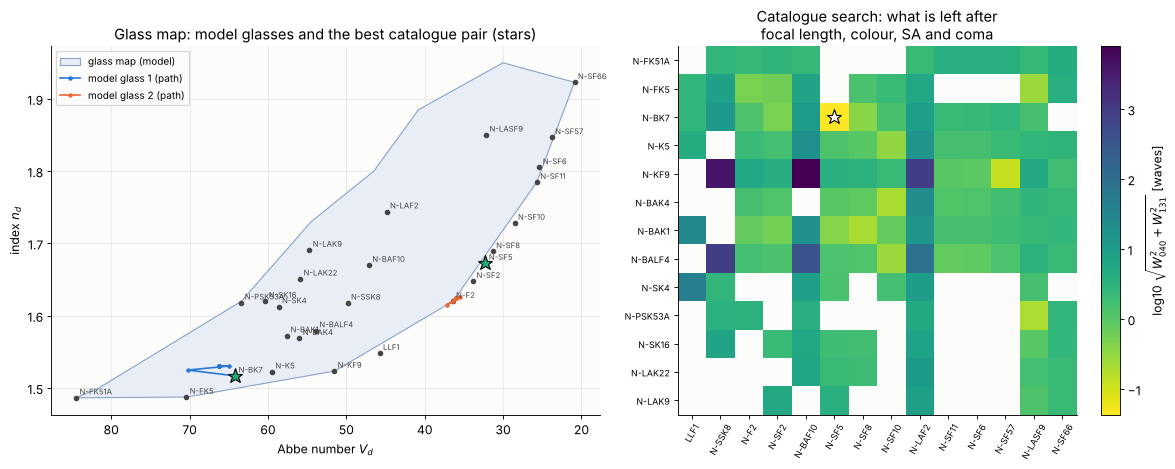

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})
outline = np.vstack([lo.GLASS_MAP, lo.GLASS_MAP[:1]])
ax1.fill(outline[:, 1], outline[:, 0], color="#e9eef6", ec="#8aa2c8", lw=1, label="glass map (model)")
for k, (n, V) in lo.GLASSES.items():
    ax1.plot(V, n, "o", color="#444", ms=4)
    ax1.annotate(k, (V, n), xytext=(3, 3), textcoords="offset points", fontsize=7, color="#444")
for j, col in [(0, "#2a78d6"), (1, "#eb6834")]:
    ax1.plot(glass_path[:, 2*j + 1], glass_path[:, 2*j], "-o", color=col, ms=3,
             label=f"model glass {j + 1} (path)")
for name, mk in [(best_pair[0], "*"), (best_pair[1], "*")]:
    n, V = lo.GLASSES[name]
    ax1.plot(V, n, mk, color="#1baf7a", ms=14, mec="k")
ax1.invert_xaxis()
ax1.set_xlabel("Abbe number $V_d$")
ax1.set_ylabel("index $n_d$")
ax1.set_title("Glass map: model glasses and the best catalogue pair (stars)")
ax1.legend(loc="upper left", fontsize=9)

im = ax2.imshow(np.log10(residual), cmap="viridis_r", aspect="auto")
ax2.set_xticks(range(len(flints)), flints, rotation=60, fontsize=8)
ax2.set_yticks(range(len(crowns)), crowns, fontsize=8)
ax2.plot(b, a, "w*", ms=14, mec="k")
ax2.grid(False)
fig.colorbar(im, ax=ax2, label=r"log10 $\sqrt{W_{040}^2 + W_{131}^2}$ [waves]")
ax2.set_title("Catalogue search: what is left after\nfocal length, colour, SA and coma")
fig.tight_layout()

The aplanatic pairs lie on a band through the catalogue: for each crown
there is a flint of the right dispersion and index. N-BK7 with N-SF5, the
best pair here, is a classic. The model glass optimization did find the
right *direction* (the model flint moved to higher index and lower Abbe
number, towards the SF glasses), but it stopped at the first point where
both aberrations vanish, which lies on the rim of the glass map (its
constraint is active). The solutions form a line in the space of the two
glasses, and DLS takes the one nearest to the start.

### 2.4 Real rays at three wavelengths

Seidel sums are third order and paraxial colour is first order. The last
step uses real rays: transverse ray errors at F, d and C, relative to the
d chief ray (so that lateral colour counts), on four rings of the pupil
at three fields, with the curvatures and the image distance as variables
(the image plane may now balance spherical aberration with defocus), the
focal length still a constraint. The curvatures from the Seidel solution
are the start.

In [9]:
s0 = doublet(*[lo.GLASSES[k] for k in best_pair])
seidel_opt = lo.DampedLeastSquares(s0, lo.curvatures(s0), ops_aplanat, cons, solves=focus)
seidel_doublet = seidel_opt.run().system
ray_ops = [lo.polychromatic_ray_errors([WL_F, WL_d, WL_C], fields=(0.0, 0.7, 1.0),
                                       tolerance=1e-3)]
real_opt = lo.DampedLeastSquares(seidel_doublet,
                                 lo.curvatures(seidel_doublet) + [lo.Thickness(2)], ray_ops,
                                 [efl_constraint()])
res_real = real_opt.run()
achromat = res_real.system
print(res_real.message, "after", len(res_real.history) - 1, "iterations")
print("merit: Seidel solution {:.4g}, real ray optimum {:.4g}".format(
    real_opt.merit(seidel_doublet), res_real.merit))
print(achromat)
for name, s in [("best singlet", best_singlet), ("achromat (Seidel)", seidel_doublet),
                ("achromat (real rays)", achromat)]:
    rms = [s.spot_diagram(f*s.max_field).rms*1e3 for f in (0.0, 1.0)]
    wf = [s.rms_opd(f*s.max_field) for f in (0.0, 1.0)]
    print(f"{name:22s} d spot RMS {rms[0]:6.2f} / {rms[1]:6.2f} um, "
          f"wavefront RMS {wf[0]:.3f} / {wf[1]:.3f} waves (axis / 1°)")

converged after 11 iterations
merit: Seidel solution 6562, real ray optimum 616.6
System(wavelength=0.0005875618, stop_index=0, object_distance=inf, max_field=0.017453292519943295)
   0* Surface(R=61.386100172474976, thickness=5.0, n_after=None, material=(1.5168, 64.17), conic=0.0, aspheric=(), semi_diameter=10.0) n'=1.516800
   1  Surface(R=-44.82672451582687, thickness=2.5, n_after=None, material=(1.67271, 32.25), conic=0.0, aspheric=(), semi_diameter=None) n'=1.672710
   2  Surface(R=-130.77102834165498, thickness=96.3922176714872, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
best singlet           d spot RMS  51.23 /  53.94 um, wavefront RMS 1.261 / 1.355 waves (axis / 1°)
achromat (Seidel)      d spot RMS   3.28 /   2.06 um, wavefront RMS 0.058 / 0.072 waves (axis / 1°)
achromat (real rays)   d spot RMS   1.95 /   1.72 um, wavefront RMS 0.083 / 0.056 waves (axis / 1°)


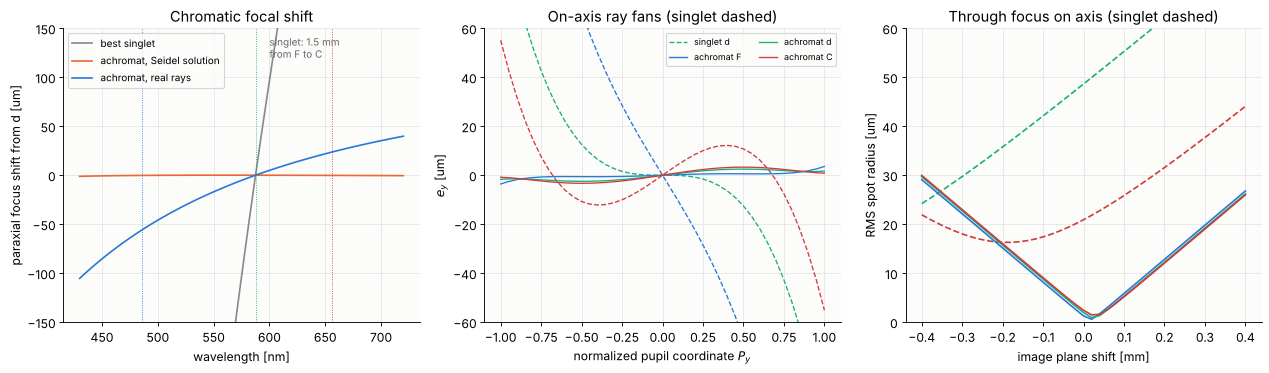

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
for name, s, col in [("best singlet", best_singlet, "#888"),
                     ("achromat, Seidel solution", seidel_doublet, "#eb6834"),
                     ("achromat, real rays", achromat, "#2a78d6")]:
    ref = s.paraxial().image_distance
    z = np.array([s.with_wavelength(w).paraxial().image_distance for w in wl_scan]) - ref
    ax.plot(wl_scan*1e6, z*1e3, color=col, label=name)
for k, w in [("F", WL_F), ("d", WL_d), ("C", WL_C)]:
    ax.axvline(w*1e6, color=COLORS[k], lw=0.8, ls=":")
ax.set_ylim(-150, 150)
ax.annotate("singlet: 1.5 mm\nfrom F to C", (600, 120), fontsize=9, color="#666")
ax.set_xlabel("wavelength [nm]")
ax.set_ylabel("paraxial focus shift from d [um]")
ax.set_title("Chromatic focal shift")
ax.legend(fontsize=9)

ax = axes[1]
for s, ls, name in [(best_singlet, "--", "singlet"), (achromat, "-", "achromat")]:
    for k, w in [("F", WL_F), ("d", WL_d), ("C", WL_C)]:
        fan = s.with_wavelength(w).ray_fan(0.0, N=41)
        ax.plot(fan.p, fan.ey*1e3, ls, color=COLORS[k], lw=1.2,
                label=f"{name} {k}" if s is achromat or k == "d" else None)
ax.set_ylim(-60, 60)
ax.set_xlabel("normalized pupil coordinate $P_y$")
ax.set_ylabel("$e_y$ [um]")
ax.set_title("On-axis ray fans (singlet dashed)")
ax.legend(fontsize=8, ncol=2)

ax = axes[2]
z = np.linspace(-0.4, 0.4, 41)
for s, ls in [(best_singlet, "--"), (achromat, "-")]:
    for k, w in [("F", WL_F), ("d", WL_d), ("C", WL_C)]:
        sw = s.with_wavelength(w)
        rms = [sw.with_image_distance(s.surfaces[-1].thickness + dz).spot_diagram(0.0, N=15).rms
               for dz in z]
        ax.plot(z, np.array(rms)*1e3, ls, color=COLORS[k])
ax.set_ylim(0, 60)
ax.set_xlabel("image plane shift [mm]")
ax.set_ylabel("RMS spot radius [um]")
ax.set_title("Through focus on axis (singlet dashed)")
fig.tight_layout()

The Seidel solution brings the paraxial F and C foci together. What is
left is the **secondary spectrum**, the parabola of the focal shift with
its vertex between F and C: the partial dispersions of crown and flint
differ, so only two wavelengths can be made to meet, and the others focus
a few tens of µm away (roughly $f/2000$ for ordinary glasses). Correcting
it needs glasses with anomalous partial dispersion (an apochromat).

The real ray optimum is no longer paraxially achromatic: its paraxial F
focus lies in front of the C focus. Spherical aberration differs with the
wavelength (*spherochromatism*), and the real rays meet best when the
colours are corrected for a zone of the pupil rather than for the
paraxial rays, as the ray fans show: F, d and C cross near the zone and
stay within a few µm over the whole pupil, against tens of µm for the
singlet. Through focus the three colours reach their smallest spots at
the same image plane.

## 3. A Cooke triplet

Taylor's triplet (1893) is the simplest anastigmat: two positive crown
lenses outside and a negative flint in the middle, near the stop. Its
eight degrees of freedom (six curvatures, two air spaces) just suffice to
set the focal length and correct the seven primary aberrations (spherical,
coma, astigmatism, Petzval, distortion, axial and lateral colour) with
fixed glasses. Here: f = 50 mm, F/4.5, ±20° field, N-SK16 and N-F2.

The start is a rough guess, no predesign: lenses of about the right power
and spacing. Variables are five curvatures (the sixth is solved for the
focal length), the air spaces around the negative lens and the stop, and
the image distance. Solves keep the focal length and the entrance pupil
(F/4.5). Operands are the real transverse ray errors at F, d and C on
axis, at 0.7 and at full field (tolerance 10 µm). Constraints: edge
thicknesses of at least 1 mm for the three lenses at the rim of the beam
and a length of at most 60 mm from the first vertex to the image. (A worse
start, which loses rays at the edge of the field, would be optimized in
stages of growing field, as the KrF lens of notebook 43.)

In [11]:
SK16, F2 = lo.GLASSES["N-SK16"], lo.GLASSES["N-F2"]
EPD, EFL, FIELD = 50/4.5, 50.0, np.deg2rad(20.0)
S = [rt.Surface(25.0, 4.0, material=SK16), rt.Surface(-300.0, 5.0, n_after=1.0),
     rt.Surface(-30.0, 1.5, material=F2), rt.Surface(30.0, 2.0, n_after=1.0),
     rt.Surface(np.inf, 3.0, semi_diameter=4.0),
     rt.Surface(100.0, 4.0, material=SK16), rt.Surface(-25.0, 40.0, n_after=1.0)]
triplet_start = rt.System(S, 4, WL_d, field_angle=FIELD, entrance_pupil_radius=EPD/2)
solves = [lo.solve_curvature_for_efl(6, EFL), lo.solve_entrance_pupil(EPD/2)]
variables = [lo.Curvature(i) for i in (0, 1, 2, 3, 5)] + \
    [lo.Thickness(1, (0.5, None)), lo.Thickness(3, (0.5, None)), lo.Thickness(4, (0.5, None)),
     lo.Thickness(6)]
operands = [lo.polychromatic_ray_errors([WL_F, WL_d, WL_C], fields=(0.0, 0.7, 1.0),
                                        tolerance=0.01)]
constraints = [lo.Constraint(lo.edge_thickness(i), lower=1.0, tolerance=0.01, name=f"edge {i}")
               for i in (0, 2, 5)]
constraints += [lo.Constraint(lo.total_length, upper=60.0, tolerance=0.01, name="length")]

opt_tr = lo.DampedLeastSquares(triplet_start, variables, operands, constraints, solves)
triplet_start = opt_tr.system.copy()  # with the solves applied
start_merit = opt_tr.merit()
t0 = time.time()
res_tr = opt_tr.run(max_iterations=40, ftol=1e-6)
print(f"{res_tr.message} after {len(res_tr.history) - 1} iterations, merit {start_merit:.4g} -> "
      f"{res_tr.merit:.4g} ({time.time() - t0:.0f} s)")
triplet = res_tr.system
print(opt_tr.report(["ray errors F, d, C"]))
print(triplet)
p = triplet.paraxial()
print(f"efl {p.efl:.3f} mm, F/{p.f_number:.2f}, length {lo.total_length(triplet):.2f} mm")

converged after 14 iterations, merit 7328 -> 568.5 (13 s)
merit function 568.543
  ray errors F, d, C                 568.54   100.0 %
  edge 0                       [1.]  [1.0, None]  ok
  edge 2                       [2.68336]  [1.0, None]  ok
  edge 5                       [1.93199]  [1.0, None]  ok
  length                       [60.]  [None, 60.0]  ok
System(wavelength=0.0005875618, stop_index=4, object_distance=inf, max_field=0.3490658503988659)
   0  Surface(R=21.154101435904455, thickness=4.0, n_after=None, material=(1.62041, 60.32), conic=0.0, aspheric=(), semi_diameter=None) n'=1.620410
   1  Surface(R=-470.253309843008, thickness=5.306697133775156, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
   2  Surface(R=-27.499841785186373, thickness=1.5, n_after=None, material=(1.62005, 36.43), conic=0.0, aspheric=(), semi_diameter=None) n'=1.620050
   3  Surface(R=19.902640069554245, thickness=0.5000007838048173, n_after=1.0, material=None, conic

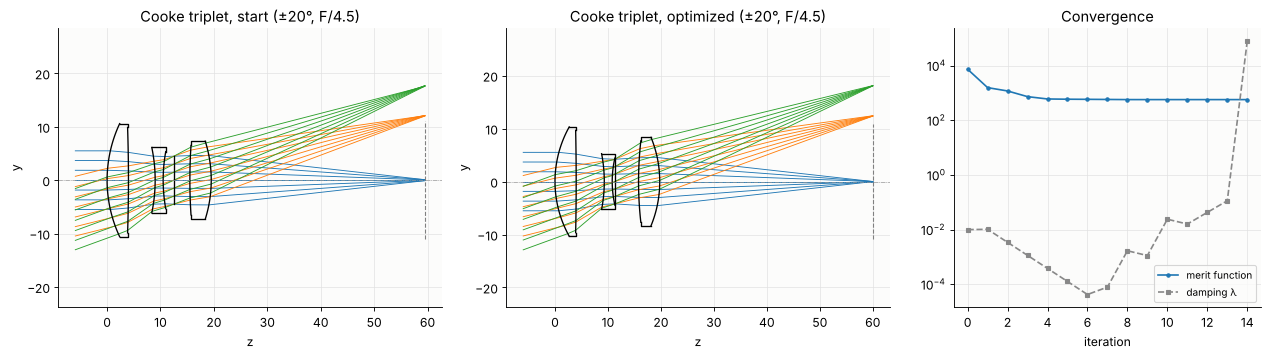

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.8]})
for ax, s, title in [(axes[0], triplet_start, "start"), (axes[1], triplet, "optimized")]:
    s.draw(ax, fields=[0.0, 0.7*s.max_field, s.max_field], n_rays=7)
    ax.set_title(f"Cooke triplet, {title} (±20°, F/4.5)")
    ax.set_aspect("equal")
ax = axes[2]
ax.semilogy([e["merit"] for e in res_tr.history], "o-", ms=3, label="merit function")
ax.semilogy([e["damping"] for e in res_tr.history], "s--", ms=3, color="#888", label="damping λ")
ax.set_xlabel("iteration")
ax.set_title("Convergence")
ax.legend(fontsize=9)
fig.tight_layout()

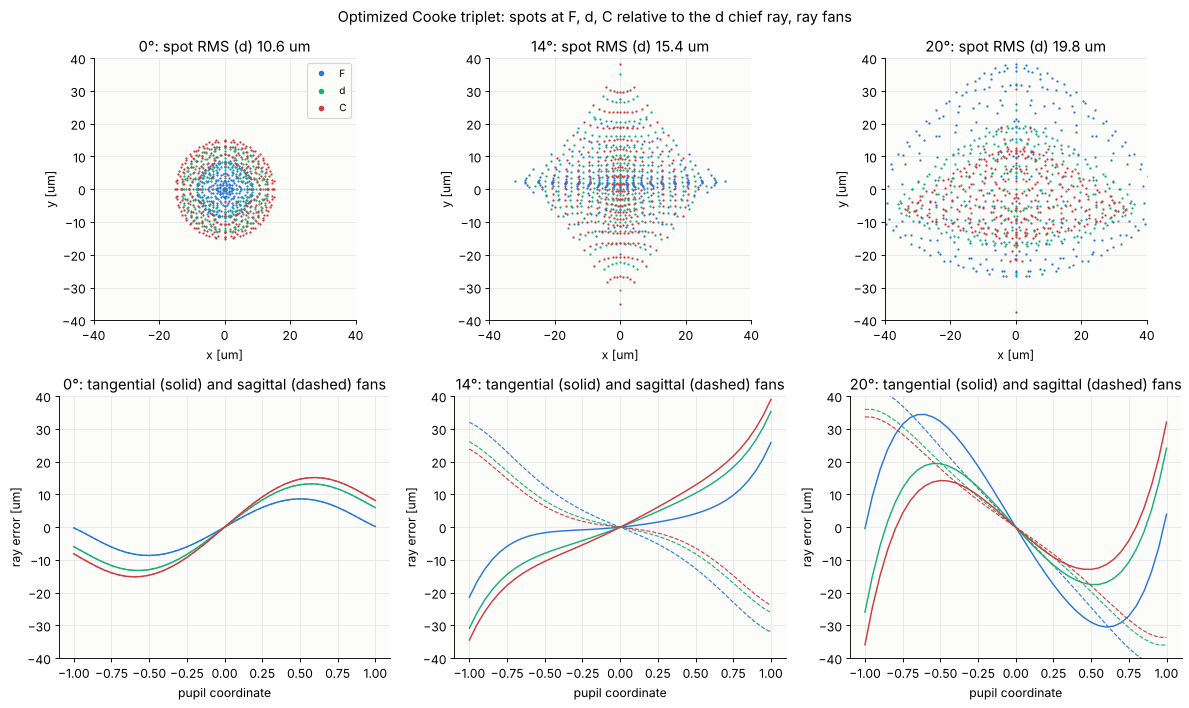

In [13]:
fields_deg = [0.0, 14.0, 20.0]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, fd in enumerate(fields_deg):
    f = np.deg2rad(fd)
    ax = axes[0, j]
    chief = triplet.spot_diagram(f, N=21)
    for kname, w in [("F", WL_F), ("d", WL_d), ("C", WL_C)]:
        sw = triplet.with_wavelength(w)
        # spots relative to the d chief ray (lateral colour shows as a shift)
        rays = sw.trace_pupil(f, *np.meshgrid(np.linspace(-1, 1, 21), np.linspace(-1, 1, 21)))
        I = sw._image_hits(rays)[0]
        I_d = triplet._image_hits(triplet.trace_pupil(f, 0.0, 0.0))[0][0]
        ok = np.all(np.isfinite(I), axis=1)
        ax.plot((I[ok, 0] - I_d[0])*1e3, (I[ok, 1] - I_d[1])*1e3, ".", ms=2, color=COLORS[kname],
                label=kname)
    ax.set_aspect("equal")
    ax.set_xlim(-40, 40)
    ax.set_ylim(-40, 40)
    ax.set_title(f"{fd:.0f}°: spot RMS (d) {chief.rms*1e3:.1f} um")
    ax.set_xlabel("x [um]")
    ax.set_ylabel("y [um]")
    if j == 0:
        ax.legend(fontsize=9, markerscale=4)
    ax = axes[1, j]
    for kname, w in [("F", WL_F), ("d", WL_d), ("C", WL_C)]:
        fan = triplet.with_wavelength(w).ray_fan(f, N=41)
        ax.plot(fan.p, fan.ey*1e3, color=COLORS[kname], lw=1.3)
        ax.plot(fan.p, fan.ex*1e3, "--", color=COLORS[kname], lw=1.0)
    ax.set_ylim(-40, 40)
    ax.set_xlabel("pupil coordinate")
    ax.set_ylabel("ray error [um]")
    ax.set_title(f"{fd:.0f}°: tangential (solid) and sagittal (dashed) fans")
fig.suptitle("Optimized Cooke triplet: spots at F, d, C relative to the d chief ray, ray fans")
fig.tight_layout()

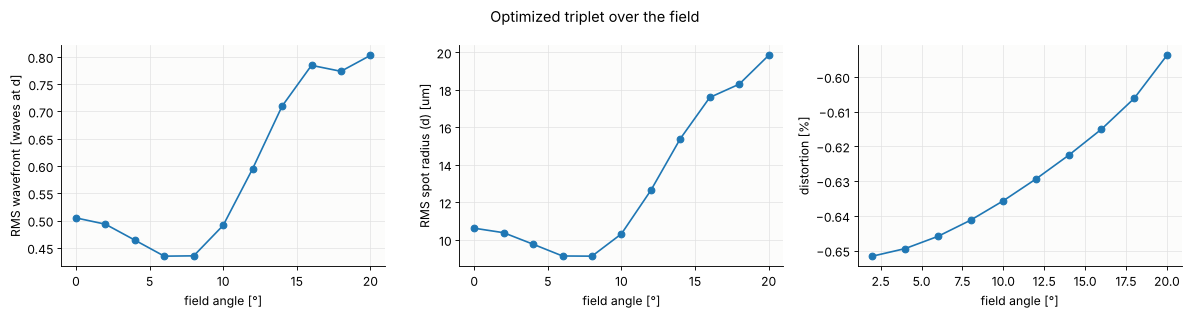

In [14]:
fields = np.linspace(0, 1, 11)
rms_wf = [triplet.rms_opd(f*FIELD) for f in fields]
spot = [triplet.spot_diagram(f*FIELD, N=21).rms*1e3 for f in fields]
p = triplet.paraxial()
dist = []
for f in fields[1:]:
    y_real = triplet._image_hits(triplet.trace_pupil(f*FIELD, 0.0, 0.0))[0][0, 1]
    y_par = p.efl*np.tan(f*FIELD)
    dist.append(100*(y_real - y_par)/y_par)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(fields*20, rms_wf, "o-")
axes[0].set_ylabel("RMS wavefront [waves at d]")
axes[1].plot(fields*20, spot, "o-")
axes[1].set_ylabel("RMS spot radius (d) [um]")
axes[2].plot(fields[1:]*20, dist, "o-")
axes[2].set_ylabel("distortion [%]")
for ax in axes:
    ax.set_xlabel("field angle [°]")
fig.suptitle("Optimized triplet over the field")
fig.tight_layout()

The optimizer found the familiar form of the triplet in 14 iterations
(the damping rises at the end, when the linear model no longer predicts
the small remaining gains): a nearly plano-convex front crown, a
biconcave flint just in front of the stop and a rear crown with its
strong side towards the image, with spots of 10-20 µm over the whole
±20° field at F/4.5. What is left is mostly higher order aberration, which
the eight degrees of freedom of a triplet can only balance against the
third order, not remove. Distortion was not an operand and stays below
1 % because the lens is nearly symmetric about the stop.

### 3.1 The Jacobian as a table of sensitivities

Each column of the Jacobian is the change of all operands for a unit
change of one variable, exactly what a tolerance analysis computes. For
operands that are the Seidel sums and the primary colours the table reads
like the designer's rules: which variable controls which aberration. Each
row is normalized to its largest entry.

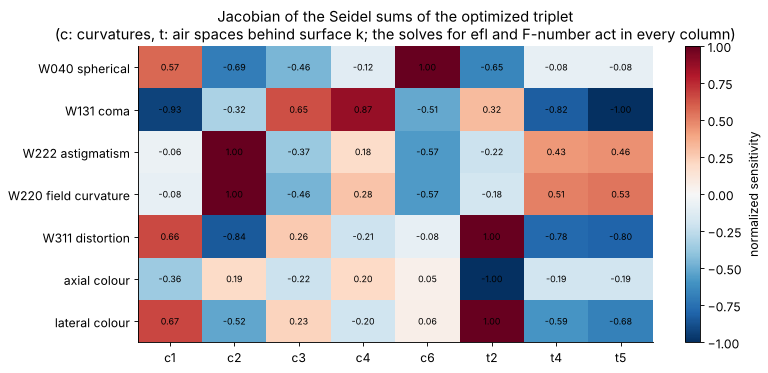

In [15]:
seidel_ops = [lo.seidel(t, 0.0, 1.0) for t in ("W040", "W131", "W222", "W220", "W311")]
seidel_ops += [lo.chromatic("axial", WL_C - WL_F, 0.0, WL_d),
               lo.chromatic("lateral", WL_C - WL_F, 0.0, WL_d)]
row_names = ["W040 spherical", "W131 coma", "W222 astigmatism", "W220 field curvature",
             "W311 distortion", "axial colour", "lateral colour"]
lens_vars = variables[:-1]  # the image distance does not change the Seidel sums
sens = lo.DampedLeastSquares(triplet, lens_vars, seidel_ops, solves=solves)
Js = sens.jacobian()[0]*sens._scale  # per typical change of each variable
col_names = [f"c{v.surface + 1}" if isinstance(v, lo.Curvature) else f"t{v.surface + 1}"
             for v in lens_vars]
fig, ax = plt.subplots(figsize=(10, 4.8))
norm = Js/np.max(np.abs(Js), axis=1, keepdims=True)
im = ax.imshow(norm, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(col_names)), col_names)
ax.set_yticks(range(len(row_names)), row_names)
for i in range(norm.shape[0]):
    for j in range(norm.shape[1]):
        ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="normalized sensitivity")
ax.set_title("Jacobian of the Seidel sums of the optimized triplet\n"
             "(c: curvatures, t: air spaces behind surface k; the solves for efl and F-number act in every column)")
fig.tight_layout()

Because the focal length is held by the last curvature, every column is a
*bending* or a shift at constant power. The air spaces move the lenses
relative to the stop: the space between the front lens and the flint (t2)
drives distortion and both colours, the spaces on either side of the stop
(t4, t5) mostly coma, distortion and lateral colour, the aberrations that
are odd in the field and that a symmetric arrangement about the stop
cancels (the symmetry principle). Astigmatism and field curvature have
nearly the same rows: the Petzval sum depends only on the powers and
indices, so the spacings change $W_{220}$ through astigmatism alone. The
curvatures change everything at once, which is why $J^\mathsf{T} J$ is
badly conditioned and a damped step is needed.

### 3.2 Who corrects what: Seidel sums per surface and pupil closeness

The surfaces contribute terms of a hundred waves and more, of opposite
signs, which add up to a few waves. The pupil closeness
$|y|/(|y| + |\bar y|)$ (`System.pupil_closeness()`) shows the layout: all
surfaces are rather close to the stop (0.55-0.95), the flint closest. The
two flint surfaces (3, 4) contribute the positive (overcorrecting) share
of spherical aberration, astigmatism and field curvature, the crown
surfaces the negative share. The sums are not zero: the real ray optimum
keeps a few waves of third order aberration to balance the higher orders.

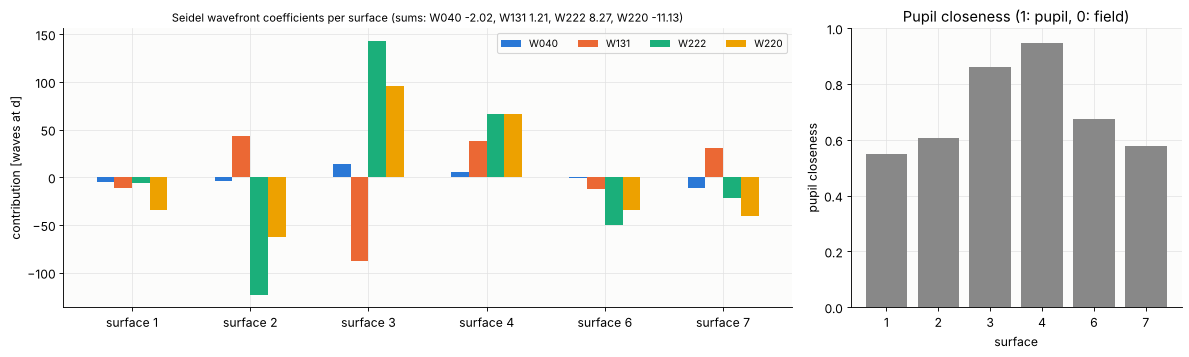

In [16]:
sd = triplet.seidel()
closeness = triplet.pupil_closeness()
labels = ["W040", "W131", "W222", "W220"]
surf = [0, 1, 2, 3, 5, 6]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
width = 0.15
for k, (lab, col) in enumerate(zip(labels, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])):
    ax1.bar(np.arange(len(surf)) + (k - 1.5)*width, sd.W[surf, k], width, color=col, label=lab)
ax1.set_xticks(range(len(surf)), [f"surface {i + 1}" for i in surf])
ax1.set_ylabel("contribution [waves at d]")
ax1.legend(ncol=5, fontsize=9)
ax1.set_title("Seidel wavefront coefficients per surface (sums: " +
              ", ".join(f"{lab} {v:.2f}" for lab, v in
                        zip(labels, [sd.W040, sd.W131, sd.W222, sd.W220])) + ")",
              fontsize=10)
ax2.bar(range(len(surf)), closeness[surf], color="#888")
ax2.set_xticks(range(len(surf)), [str(i + 1) for i in surf])
ax2.set_ylim(0, 1)
ax2.set_xlabel("surface")
ax2.set_ylabel("pupil closeness")
ax2.set_title("Pupil closeness (1: pupil, 0: field)")
fig.tight_layout()

### 3.3 The Lagrange multiplier: the price of a constraint

At the optimum the multiplier $\mu$ of an active constraint says how much
the merit function would gain if the constraint were relaxed: for a bound
$g \le b$, $\partial \Phi/\partial b = -2\mu$ (the factor 2 because the
merit function is the sum of squares, without the 1/2). The length
constraint is active. Relaxing it by 1 mm and optimizing again tests the
prediction.

In [17]:
print("active constraints and multipliers:",
      {k: round(float(v), 3) for k, v in res_tr.multipliers.items()})
mu = res_tr.multipliers["length"]
print(" relaxed by   predicted change   optimized change")
for d in (0.1, 0.3, 1.0):
    relaxed = constraints[:-1] + [lo.Constraint(lo.total_length, upper=60.0 + d, tolerance=0.01,
                                                name="length")]
    r = lo.DampedLeastSquares(triplet, variables, operands, relaxed, solves).run(
        max_iterations=40, ftol=1e-7)
    print(f"   {d:4.1f} mm     {-2*mu*d:12.2f}     {r.merit - res_tr.merit:12.2f}")

active constraints and multipliers: {'edge 0': -20.962, 'length': 18.988}
 relaxed by   predicted change   optimized change


    0.1 mm            -3.80            -4.06


    0.3 mm           -11.39           -10.71


    1.0 mm           -37.98           -12.87


The prediction is a first order one: it holds for small changes and
overestimates the gain of a large one, as the multiplier itself falls
when the constraint is relaxed. But it tells the designer without any
further optimization whether a constraint is expensive. Here the length
is moderately expensive: 0.3 mm more length lower the merit function by
about 2 %.

## 4. A microscope objective

A 10x/0.25 objective for an infinity corrected microscope: with a tube
lens of 200 mm the focal length is f = 20 mm, the numerical aperture 0.25
needs an entrance pupil of $2 f\,\mathrm{NA} = 10$ mm, and a field number
of 20 mm in the intermediate image is a field of ±1 mm in the specimen.
The specimen lies under a standard cover glass (0.17 mm, D 263, $n_d = 1.523$,
$V_d = 55$), and the working distance from the last vertex to the cover
glass must be at least 5 mm.

The lens is designed as it is traced: light comes from infinity (the tube
lens side) through the stop, the back focal plane where the objective's
aperture sits, and is focused into the specimen. The diffraction limit
sets the scale: the Airy radius is $0.61\,\lambda/\mathrm{NA} = 1.3$ µm,
the depth of focus $\lambda/\mathrm{NA}^2 \approx 9$ µm, and an objective is
*diffraction limited* where the Strehl ratio is above 0.8, the
Maréchal criterion of an RMS wavefront error below λ/14.
The operand is therefore the RMS wavefront error itself (`lo.wavefront`),
at F, d and C on axis, at 0.7 and at full field, with a tolerance of
0.02 waves.

### 4.1 The Lister objective: two achromats

The classical low power objective (J. J. Lister, 1830) is two cemented
achromats in a row, each taking about half of the power. Each doublet
bends the light a little, so the spherical aberration of the pair is far
smaller than that of one doublet of the full power, and the spacing gives
a degree of freedom for coma. The glasses are N-BAK4 and N-SF5 from the
catalogue of `pyoptics.glasses` (notebook 61). Variables: five curvatures
(the last one of the rear doublet is solved for the focal length) and the
air space between the doublets. The air space in front of the cover glass
is solved for the paraxial focus (`lo.solve_paraxial_focus(surface=...)`
moves everything behind it); a constraint keeps it at 5 mm or more.

In [18]:
from pyoptics import glasses as gl

F_OBJ, NA, FIELD_OBJ = 20.0, 0.25, 1.0  # focal length, NA, field radius in the specimen [mm]
EPD_OBJ = 2*F_OBJ*NA
COVER = (1.5230, 55.0)  # D 263 cover glass
WLS = [WL_F, WL_d, WL_C]


def objective(surfaces, wavelength=WL_d):
    return rt.System(surfaces, 0, wavelength, field_angle=np.arctan(FIELD_OBJ/F_OBJ),
                     entrance_pupil_radius=EPD_OBJ/2)


def cover_glass(working_distance=5.0):
    return [rt.Surface(np.inf, working_distance, n_after=1.0),
            rt.Surface(np.inf, 0.17, material=COVER), rt.Surface(np.inf, 0.0, n_after=1.0)]


crown, flint = gl.get("N-BAK4"), gl.get("N-SF5")
S = [rt.Surface(np.inf, 2.0, semi_diameter=EPD_OBJ/2),  # stop: the back aperture
     rt.Surface(25.0, 4.0, material=crown), rt.Surface(-18.0, 1.5, material=flint),
     rt.Surface(-150.0, 4.0, n_after=1.0),
     rt.Surface(10.0, 4.0, material=crown), rt.Surface(-9.0, 1.5, material=flint),
     ] + cover_glass()
S[6].R = -60.0  # rear doublet, last surface, followed by the working distance
lister_start = objective(S)
WD = 6  # the air space in front of the cover glass

solves_obj = [lo.solve_curvature_for_efl(WD, F_OBJ), lo.solve_paraxial_focus(surface=WD)]
operands_obj = [lo.wavefront(fields=(0.0, 0.7, 1.0), wavelengths=WLS, tolerance=0.02)]


def objective_constraints(lenses, air):
    cons = [lo.Constraint(lo.center_thickness(WD), lower=5.0, tolerance=0.01, name="working distance"),
            lo.Constraint(lo.total_length, upper=40.0, tolerance=0.01, name="length")]
    cons += [lo.Constraint(lo.edge_thickness(i), lower=1.0, tolerance=0.01, name=f"edge {i}")
             for i in lenses]
    cons += [lo.Constraint(lo.edge_thickness(i), lower=0.5, tolerance=0.01, name=f"air edge {i}")
             for i in air]
    return cons


variables = [lo.Curvature(i) for i in (1, 2, 3, 4, 5)] + [lo.Thickness(3, (0.5, None))]
opt_li = lo.DampedLeastSquares(lister_start, variables, operands_obj,
                               objective_constraints(lenses=(1, 4), air=(3,)), solves_obj)
lister_start = opt_li.system.copy()
start_merit = opt_li.merit()
t0 = time.time()
res_li = opt_li.run(max_iterations=60)
lister = res_li.system
print(f"{res_li.message} after {len(res_li.history) - 1} iterations, merit {start_merit:.4g} -> "
      f"{res_li.merit:.4g} ({time.time() - t0:.0f} s)")
print(lister)


def objective_summary(s, name, wd):
    p = s.paraxial()
    to = s.third_order()
    print(f"{name}: efl {p.efl:.3f} mm, NA {EPD_OBJ/2/p.efl:.3f}, "
          f"working distance {s.surfaces[wd].thickness:.2f} mm, length {lo.total_length(s):.1f} mm, "
          f"Petzval radius {to.petzval_radius:.1f} mm")
    for f in (0.0, 0.7, 1.0):
        print(f"  field {f*FIELD_OBJ:.1f} mm: RMS wavefront F/d/C " +
              "/".join(f"{s.with_wavelength(w).rms_opd(f*s.max_field):.3f}" for w in WLS) +
              f" waves, Strehl (d) {s.strehl(f*s.max_field):.2f}")


objective_summary(lister, "Lister", 6)

converged after 34 iterations, merit 7.496e+07 -> 3.9e+04 (19 s)
System(wavelength=0.0005875618, stop_index=0, object_distance=inf, max_field=0.049958395721942765)
   0* Surface(R=inf, thickness=2.0, n_after=None, material=None, conic=0.0, aspheric=(), semi_diameter=5.0) n'=1.000000
   1  Surface(R=20.734151803036255, thickness=4.0, n_after=None, material=Glass('N-BAK4', SCHOTT, n_d=1.56883, V_d=55.98), conic=0.0, aspheric=(), semi_diameter=None) n'=1.568827
   2  Surface(R=-15.490805820411326, thickness=1.5, n_after=None, material=Glass('N-SF5', SCHOTT, n_d=1.67271, V_d=32.25), conic=0.0, aspheric=(), semi_diameter=None) n'=1.672707
   3  Surface(R=-150.64688353525318, thickness=19.130117908036375, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
   4  Surface(R=9.507896298492932, thickness=4.0, n_after=None, material=Glass('N-BAK4', SCHOTT, n_d=1.56883, V_d=55.98), conic=0.0, aspheric=(), semi_diameter=None) n'=1.568827
   5  Surface(R=-8.8432172959

  field 0.7 mm: RMS wavefront F/d/C 0.152/0.143/0.081 waves, Strehl (d) 0.43
  field 1.0 mm: RMS wavefront F/d/C 0.280/0.275/0.194 waves, Strehl (d) 0.11


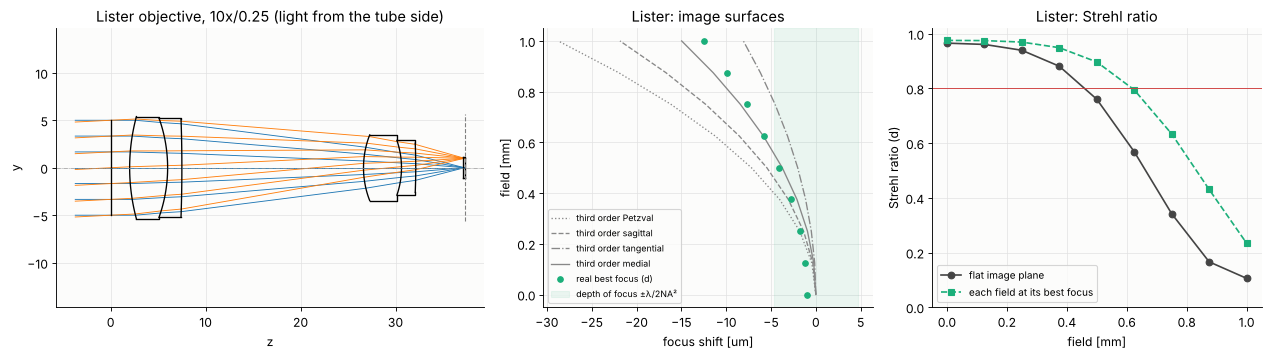

In [19]:
from scipy.optimize import minimize_scalar


def best_focus(s, field):
    """Image plane shift [mm] of least RMS wavefront error (d) at a field."""
    r = minimize_scalar(lambda dz: s.with_image_distance(dz).rms_opd(field),
                        bounds=(-0.08, 0.04), method="bounded", options={"xatol": 1e-5})
    return r.x, s.with_image_distance(r.x).strehl(field)


def field_curves(s, name, ax_z, ax_s):
    fr = np.linspace(0, 1, 9)
    h = fr*FIELD_OBJ
    to = s.third_order()
    for R, ls, lab in [(to.petzval_radius, ":", "Petzval"), (to.sagittal_radius, "--", "sagittal"),
                       (to.tangential_radius, "-.", "tangential"), (to.medial_radius, "-", "medial")]:
        ax_z.plot(h**2/(2*R)*1e3, h, ls, color="#888", lw=1.2, label=f"third order {lab}")
    bf = np.array([best_focus(s, f*s.max_field) for f in fr])
    ax_z.plot(bf[:, 0]*1e3, h, "o", color=COLORS["d"], ms=5, label="real best focus (d)")
    ax_z.axvspan(-4.7, 4.7, color=COLORS["d"], alpha=0.08, label="depth of focus ±λ/2NA²")
    ax_z.set_xlabel("focus shift [um]")
    ax_z.set_ylabel("field [mm]")
    ax_z.set_title(f"{name}: image surfaces")
    ax_s.plot(h, [s.strehl(f*s.max_field) for f in fr], "o-", color="#444", label="flat image plane")
    ax_s.plot(h, bf[:, 1], "s--", color=COLORS["d"], label="each field at its best focus")
    ax_s.axhline(0.8, color="#d03b3b", lw=0.8)
    ax_s.set_ylim(0, 1.02)
    ax_s.set_xlabel("field [mm]")
    ax_s.set_ylabel("Strehl ratio (d)")
    ax_s.set_title(f"{name}: Strehl ratio")


fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
lister.draw(axes[0], fields=[0.0, lister.max_field], n_rays=7)
axes[0].set_title("Lister objective, 10x/0.25 (light from the tube side)")
axes[0].set_aspect("equal")
field_curves(lister, "Lister", axes[1], axes[2])
axes[1].legend(fontsize=8)
axes[2].legend(fontsize=9)
fig.tight_layout()

The two achromats are diffraction limited on axis (Strehl 0.97 at d), but
the Strehl ratio in a flat image plane falls below 0.8 at half the field
and to about 0.1 at the edge. The best foci of the field points lie on a
bowl that is more than 10 µm deep at the edge, several depths of focus:
the image is **curved**. Refocusing for each field point recovers the
Strehl ratio out to about 0.6 mm; further out the sagittal and tangential
images separate (astigmatism) and refocusing no longer helps.

The origin is the **Petzval sum**

$$
P = \sum_k \frac{\varphi_k}{n_k}
$$

(thin lenses of power $\varphi_k$ and index $n_k$ in air; for surfaces
$\sum c\,(n'-n)/(n\,n')$). It depends neither on the bending of the
lenses nor on their positions nor on the stop, so no choice of curvatures
and spacings with the same glasses and powers can flatten the field. The
astigmatism moves the sagittal and tangential surfaces to either side of
the Petzval surface (in the ratio 1:3 in third order), and the optimizer
has used it to bring the medial surface towards the flat image plane as
far as it can. A positive objective of short focal length has a large
Petzval sum, here $P f = 1.15$, and a Petzval radius $R_P = -1/(n' P)$
shorter than the focal length. The achromatic objectives of the 19th and
early 20th century had exactly this field: sharp in the centre, refocused
for the edge.

### 4.2 A plan objective: flattening the field

There are two ways to lower $P$ while keeping the power:

- **High index positive lenses.** A positive lens contributes $\varphi/n$:
  lanthanum crowns (N-LAK22, $n_d = 1.65$) instead of barium crowns
  (N-BAK4, $n_d = 1.57$) lower the contribution of the positive
  elements. Their flint partner gets a higher index too (N-SF6) to keep
  the achromat.
- **A thick meniscus.** A meniscus whose two surfaces have nearly equal
  radii has almost no power, but its Petzval contribution
  $\frac{n-1}{n}(c_1 - c_2)$ is that of its surfaces, independent of the
  thickness. Its power, on the other hand, depends on where the marginal
  ray crosses each surface. A thick meniscus with its concave side
  towards a converging beam therefore flattens the field with little loss
  of power. This is the field flattener of the plan achromats (H. Boegehold,
  Zeiss 1938, and the plan objectives that followed).

The plan objective has the two doublets in N-LAK22/N-SF6 with a thick
N-BK7 meniscus between them. The start takes the curvatures of the Lister
objective. Variables: seven curvatures, the two air spaces and the
thicknesses of the meniscus and of the two positive lenses.

In [20]:
crown, flint, men = gl.get("N-LAK22"), gl.get("N-SF6"), gl.get("N-BK7")
L = lister.surfaces
S = [rt.Surface(np.inf, 2.0, semi_diameter=EPD_OBJ/2),
     rt.Surface(L[1].R, 4.0, material=crown), rt.Surface(L[2].R, 1.5, material=flint),
     rt.Surface(L[3].R, 3.0, n_after=1.0),
     rt.Surface(8.0, 5.0, material=men), rt.Surface(6.0, 3.0, n_after=1.0),  # meniscus
     rt.Surface(L[4].R, 4.0, material=crown), rt.Surface(L[5].R, 1.5, material=flint),
     ] + cover_glass()
S[8].R = L[6].R
plan_start = objective(S)
WD = 8
solves_obj = [lo.solve_curvature_for_efl(WD, F_OBJ), lo.solve_paraxial_focus(surface=WD)]
variables = [lo.Curvature(i) for i in range(1, 8)] + \
    [lo.Thickness(i, (0.5, None)) for i in (3, 5)] + [lo.Thickness(i, (1.0, None)) for i in (1, 4, 6)]
opt_pl = lo.DampedLeastSquares(plan_start, variables, operands_obj,
                               objective_constraints(lenses=(1, 4, 6), air=(3, 5)), solves_obj)
plan_start = opt_pl.system.copy()
start_merit = opt_pl.merit()
t0 = time.time()
res_pl = opt_pl.run(max_iterations=200)
plan = res_pl.system
print(f"{res_pl.message} after {len(res_pl.history) - 1} iterations, merit {start_merit:.4g} -> "
      f"{res_pl.merit:.4g} ({time.time() - t0:.0f} s)")
print(opt_pl.report(["RMS wavefront F, d, C"]))
objective_summary(lister, "Lister", 6)
objective_summary(plan, "plan", 8)

converged after 121 iterations, merit 8.469e+06 -> 9047 (139 s)
merit function 9046.75
  RMS wavefront F, d, C              9046.8   100.0 %
  working distance             [5.]  [5.0, None]  ok
  length                       [32.11255]  [None, 40.0]  ok
  edge 1                       [1.]  [1.0, None]  ok
  edge 4                       [15.9298]  [1.0, None]  ok
  edge 6                       [4.35411]  [1.0, None]  ok
  air edge 3                   [3.26003]  [0.5, None]  ok
  air edge 5                   [0.5]  [0.5, None]  ok
Lister: efl 20.000 mm, NA 0.250, working distance 5.00 mm, length 37.3 mm, Petzval radius -17.4 mm
  field 0.0 mm: RMS wavefront F/d/C 0.149/0.030/0.067 waves, Strehl (d) 0.97


  field 0.7 mm: RMS wavefront F/d/C 0.152/0.143/0.081 waves, Strehl (d) 0.43
  field 1.0 mm: RMS wavefront F/d/C 0.280/0.275/0.194 waves, Strehl (d) 0.11
plan: efl 20.000 mm, NA 0.250, working distance 5.00 mm, length 32.1 mm, Petzval radius -70.8 mm


  field 0.0 mm: RMS wavefront F/d/C 0.046/0.068/0.048 waves, Strehl (d) 0.83
  field 0.7 mm: RMS wavefront F/d/C 0.044/0.079/0.049 waves, Strehl (d) 0.78


  field 1.0 mm: RMS wavefront F/d/C 0.058/0.092/0.067 waves, Strehl (d) 0.72


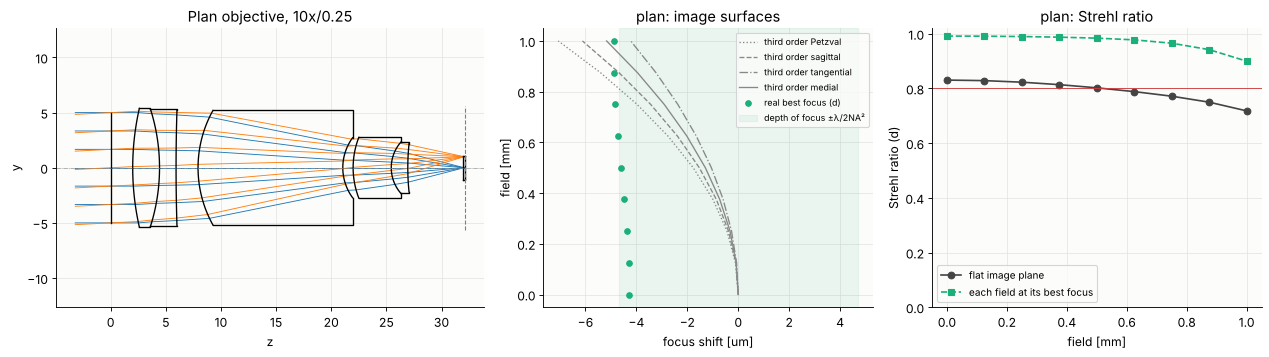

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
plan.draw(axes[0], fields=[0.0, plan.max_field], n_rays=7)
axes[0].set_title("Plan objective, 10x/0.25")
axes[0].set_aspect("equal")
field_curves(plan, "plan", axes[1], axes[2])
axes[1].legend(fontsize=8)
axes[2].legend(fontsize=9)
fig.tight_layout()

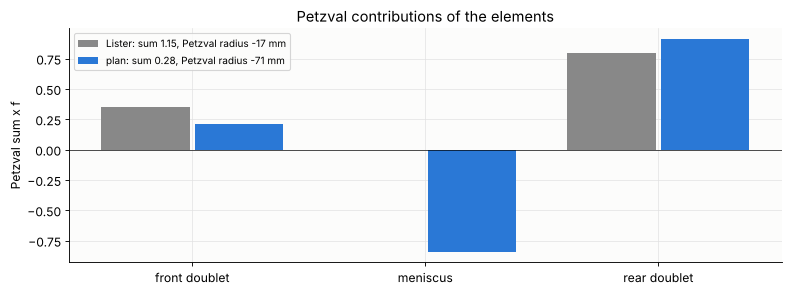

In [22]:
def petzval_terms(s, groups):
    """Petzval contributions c (n' - n)/(n n') of groups of surfaces, times the focal length."""
    n = s.n
    c = np.array([0.0 if np.isinf(x.R) else 1/x.R for x in s.surfaces])
    t = c*(n[1:] - n[:-1])/(n[1:]*n[:-1])*s.paraxial().efl
    return [t[list(g)].sum() if g else 0.0 for g in groups], t.sum()


fig, ax = plt.subplots(figsize=(10, 3.8))
for s, groups, name, col, off in [(lister, [(1, 2, 3), (), (4, 5, 6)], "Lister", "#888", -0.2),
                                  (plan, [(1, 2, 3), (4, 5), (6, 7, 8)], "plan", "#2a78d6", 0.2)]:
    terms, total = petzval_terms(s, groups)
    ax.bar(np.arange(3) + off, terms, 0.38, color=col,
           label=f"{name}: sum {total:.2f}, Petzval radius {s.third_order().petzval_radius:.0f} mm")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks([0, 1, 2], ["front doublet", "meniscus", "rear doublet"])
ax.set_ylabel("Petzval sum x f")
ax.legend(fontsize=9)
ax.set_title("Petzval contributions of the elements")
fig.tight_layout()

The meniscus has almost no power but a Petzval contribution of about
$-0.85/f$, which cancels most of the rear doublet; the lanthanum crowns
lower the front doublet. The Petzval sum falls from $1.15/f$ to $0.28/f$
and the Petzval radius grows from 17 mm to 71 mm, and the residual is
balanced by astigmatism: the real best foci now lie on a line within half
a micrometre over the whole field, a flat field.

The optimizer found the form of a plan objective without being told: a
thick meniscus of about 13 mm, concave towards the specimen, between a
weak front doublet and a strong rear doublet near the specimen. The
remaining error is not field dependent: at the fixed image plane the
Strehl ratio at d is 0.72-0.83 over the field, at its own focus it is
above 0.9 everywhere. The d focus is shifted by 4.5 µm, half the depth of
focus, because the operand weighs F, d and C equally: the optimizer has
placed the image plane between the foci of the three wavelengths, the
residual longitudinal colour (secondary spectrum, notebook 61) that an
achromat cannot remove. The RMS wavefront errors at F and C fell from
0.15 and 0.07 waves on axis (Lister) to 0.05. Real plan objectives go
further with fluorite and anomalous dispersion glasses (semi-apochromats
and apochromats) and correct the colour of the tube lens together with
the objective.

## Summary

- The merit function of a lens is a long, curved, narrow valley. Damped
  least squares with an adaptive damping takes long Gauss-Newton steps
  where the linear model holds and short steepest descent steps where it
  fails.
- The Jacobian is the table of sensitivities of the operands to the
  variables, the same as in tolerancing.
- Solves (focal length, F-number, focus) and constraints with Lagrange
  multipliers (focal length, colour, edge thicknesses, length) take
  requirements out of the merit function; the multipliers price them.
- Glasses are variables too: model glasses on the glass map show the
  direction, a catalogue search finds the real pair (N-BK7/N-SF5 for an
  aplanatic cemented achromat here).
- Seidel operands are fast and say what to correct; the final correction
  uses real rays at several wavelengths and fields.
- Some aberrations are out of reach of the optimizer within a given
  structure: the Petzval sum of the Lister objective does not depend on
  curvatures and spacings. The designer changes the structure (a thick
  meniscus, high index glasses), the optimizer finds its form.

In [23]:
print(f"run time {time.time() - t_start:.0f} s")

run time 278 s


## References

- K. Levenberg, "A method for the solution of certain non-linear problems in least squares", Q. Appl. Math. 2, 164-168 (1944).
- D. W. Marquardt, "An algorithm for least-squares estimation of nonlinear parameters", J. Soc. Ind. Appl. Math. 11, 431-441 (1963).
- C. G. Wynne, "Lens designing by electronic digital computer: I", Proc. Phys. Soc. 73, 777-787 (1959).
- C. G. Wynne and P. M. J. H. Wormell, "Lens design by computer", Appl. Opt. 2, 1233-1238 (1963).
- G. H. Spencer, "A flexible automatic lens correction procedure", Appl. Opt. 2, 1257-1264 (1963) (constraints with Lagrange multipliers).
- H. B. Nielsen, "Damping parameter in Marquardt's method", Technical Report IMM-REP-1999-05, Technical University of Denmark (1999).
- K. Madsen, H. B. Nielsen and O. Tingleff, *Methods for Non-Linear Least Squares Problems*, 2nd ed., Technical University of Denmark (2004).
- M. J. Kidger, *Fundamental Optical Design*, SPIE Press (2001) and *Intermediate Optical Design*, SPIE Press (2004) (DLS in lens design, the Cooke triplet).
- R. Kingslake and R. B. Johnson, *Lens Design Fundamentals*, 2nd ed., Academic Press (2010) (achromats, aplanatic doublets, the triplet).
- W. J. Smith, *Modern Lens Design*, 2nd ed., McGraw-Hill (2005).
- W. T. Welford, *Aberrations of Optical Systems*, Adam Hilger (1986) (Seidel sums, primary colour, secondary spectrum).
- J. J. Lister, "On some properties in achromatic object-glasses applicable to the improvement of the microscope", Phil. Trans. R. Soc. Lond. 120, 187-200 (1830).
- H. Gross (ed.), *Handbook of Optical Systems*, Vol. 4: *Survey of Optical Instruments*, Wiley-VCH (2008) (microscope objectives, plan objectives with thick menisci).
- M. Laikin, *Lens Design*, 4th ed., CRC Press (2007) (microscope objectives).
- Y. Zhang and H. Gross, "Systematic design of microscope objectives. Part I: System review and analysis", Adv. Opt. Technol. 8(5) (2019).
- H. D. Taylor, "Lens", British patent 22,607 (1893) (the Cooke triplet).
- Schott AG, *Optical Glass - Data Sheets* (nominal $n_d$, $V_d$ of the glasses used).